# ARC-AGI-2: Solver Pipeline, Benchmarking & Diagnostics

This notebook demonstrates the end-to-end neuro-symbolic solver pipeline, verification diagnostics, empirical benchmarking, and competition submission generation.

### Pipeline Subsystems Demonstrated:
1. **Hunter Symbolic Baseline**: Rapid pattern matching for common geometric/color/crop transformations.
2. **Constrained DSL Program Search**: Beam search over 45+ primitives with early constraint pruning.
3. **Verification & REPL Refinement**: Exact 100% pixel matching and failure diagnostic trace inspection.
4. **Multi-Test Task Reasoning**: Generating attempt 1 and attempt 2 candidate predictions per test query.
5. **Kaggle Submission Adapter**: Validating output schemas, dimensions, and color range constraints.


In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# Add repository root to python path
repo_root = Path("..").resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.data.dataset_loader import ArcDatasetLoader
from src.representation.grid import ArcGrid
from src.solvers.hunter import HunterBaselineSolver
from src.solvers.integrated_solver import IntegratedArcSolver
from src.search.verifier import DemonstrationVerifier, TaskDemonstration
from src.submission.adapter import SubmissionAdapter
from src.benchmark.harness import BenchmarkHarness
from src.visualization import plot_grid, plot_task

print("All solver and benchmark modules successfully imported.")


/home/naya/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


All solver and benchmark modules successfully imported.


## 1. Hunter Symbolic Baseline: Solving Task 1cf80156

Task `1cf80156` requires cropping each grid to the minimal bounding box enclosing all non-zero pixels.
We demonstrate the Hunter Baseline identifying and verifying this rule in under 20ms.


Task ID: 1cf80156
Solved by Hunter: True
Program: crop_to_content
Code: lambda g: crop_to_content(g)


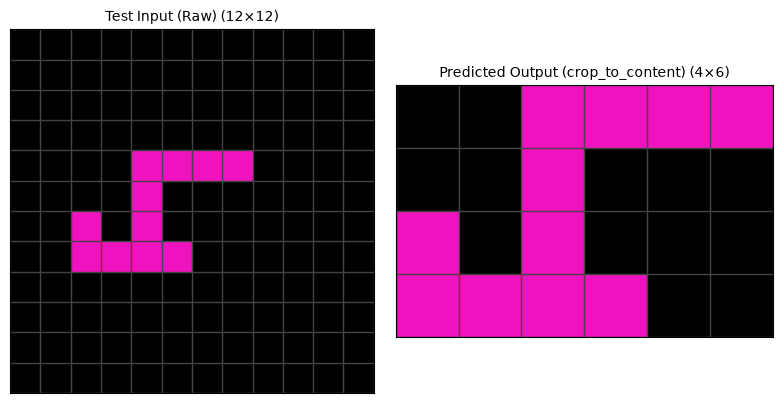

In [2]:
loader = ArcDatasetLoader(data_dir=repo_root / "data" / "raw")
task = loader.load_task("1cf80156")

hunter = HunterBaselineSolver()
prog = hunter.solve(task)

print(f"Task ID: {task.task_id}")
print(f"Solved by Hunter: {prog is not None}")
if prog:
    print(f"Program: {prog.name}")
    print(f"Code: {prog.to_code()}")

# Verify on test input
test_in = ArcGrid(np_grid=task.test_inputs[0])
test_pred = prog.execute(test_in)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
plot_grid(test_in.to_numpy(), ax=axes[0], title="Test Input (Raw)")
plot_grid(test_pred.to_numpy(), ax=axes[1], title=f"Predicted Output ({prog.name})")
plt.tight_layout()
plt.show()


## 2. DSL Program Synthesis: Solving Task 1e0a9b12

Task `1e0a9b12` requires downward gravity, causing floating colored pixels to stack at the bottom of the grid while maintaining column alignment.


Task ID: 1e0a9b12 | Solved: True
Pipeline Stage: hunter_baseline | Duration: 0.031s
Best Program: gravity_down


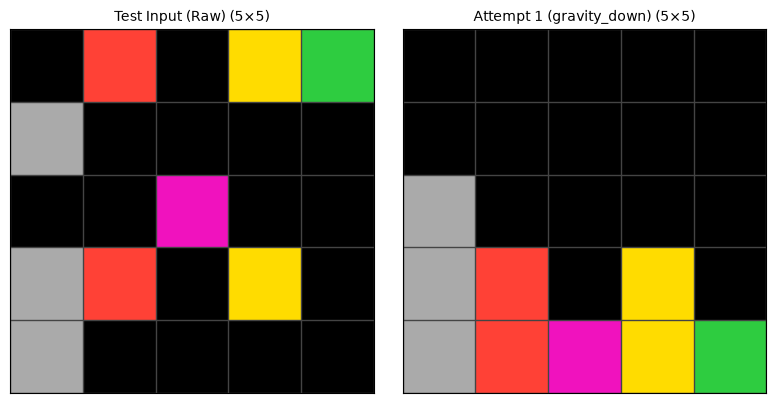

In [3]:
task_grav = loader.load_task("1e0a9b12")
solver = IntegratedArcSolver(search_timeout_seconds=2.0)
solution = solver.solve(task_grav)

print(f"Task ID: {solution.task_id} | Solved: {solution.solved}")
print(f"Pipeline Stage: {solution.solver_pipeline_stage} | Duration: {solution.execution_time_sec:.3f}s")
if solution.best_program:
    print(f"Best Program: {solution.best_program.name}")

test_in_grav = ArcGrid(np_grid=task_grav.test_inputs[0])
pred_grav = solution.test_predictions[0].attempt_1

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
plot_grid(test_in_grav.to_numpy(), ax=axes[0], title="Test Input (Raw)")
plot_grid(pred_grav.to_numpy(), ax=axes[1], title="Attempt 1 (gravity_down)")
plt.tight_layout()
plt.show()


## 3. Kaggle Competition Submission Adapter & Validation

We demonstrate running the submission adapter on test tasks to verify schema correctness, 2 attempts per query, and dimension constraints.


In [4]:
import tempfile

adapter = SubmissionAdapter(solver)
test_tasks = loader.load_test_challenges()[:5]

with tempfile.TemporaryDirectory() as tmpdir:
    sub_path = Path(tmpdir) / "submission_sample.json"
    sub_data = adapter.generate_submission(test_tasks, output_path=sub_path, dry_run=True)
    
    print(f"Generated submission file size: {sub_path.stat().st_size} bytes")
    print(f"Tasks submitted: {len(sub_data)}")
    first_task = list(sub_data.keys())[0]
    print(f"Sample Entry for {first_task}:")
    print(sub_data[first_task])


Generated submission file size: 6520 bytes
Tasks submitted: 5
Sample Entry for 00576224:
[{'attempt_1': [[7, 3], [8, 2]], 'attempt_2': [[8, 7], [2, 3]]}]
